In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch

p = print
d = display

p("PyTorch:", torch.__version__)
p("tarjeta: ", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
tarjeta:  True


In [2]:
Carpeta_Proyecto = Path.cwd().parent
Carpeta_listos = Carpeta_Proyecto / "Dataset" / "M_Listos"
p(Carpeta_listos)

/home/Ian/prediccion_red/Dataset/M_Listos


In [3]:
df_e = pd.read_csv(Carpeta_listos / "M_entre.csv")
df_p = pd.read_csv(Carpeta_listos / "M_prueb.csv")
p(df_e.shape, df_p.shape)

(60000, 785) (10000, 785)


### ### X e Y

In [4]:
Xtr = df_e.drop(columns="respuesta").values / 255.0
Ytr = df_e["respuesta"].values
Xts = df_p.drop(columns="respuesta").values / 255.0
Yts = df_p["respuesta"].values

p("Datos de entrenamiento:", len(Xtr))
p("Datos de prueba:", len(Xts))

Datos de entrenamiento: 60000
Datos de prueba: 10000


### imágenes al formato de PyTorch

In [5]:
Xtr_t = torch.tensor(Xtr, dtype=torch.float32).reshape(-1, 1, 28, 28)
Ytr_t = torch.tensor(Ytr, dtype=torch.long)
Xts_t = torch.tensor(Xts, dtype=torch.float32).reshape(-1, 1, 28, 28)
Yts_t = torch.tensor(Yts, dtype=torch.long)

p("Forma de Xtr_t:", Xtr_t.shape)
p("Forma de Ytr_t:", Ytr_t.shape)

Forma de Xtr_t: torch.Size([60000, 1, 28, 28])
Forma de Ytr_t: torch.Size([60000])


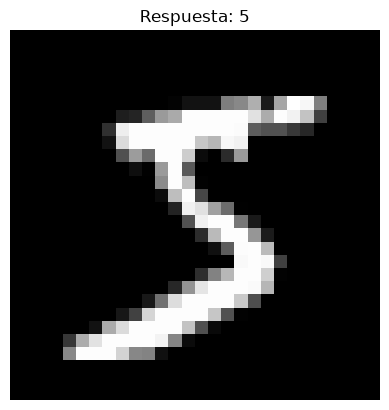

In [6]:
plt.imshow(Xtr_t[0, 0], cmap="gray")
plt.title("Respuesta: " + str(Ytr_t[0].item()))
plt.axis("off")
plt.show()

### red convolucional

In [7]:
from torch import nn


class RedConvolucional(nn.Module):
    def __init__(self, n_salidas=10, abandono=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.agrupar = nn.MaxPool2d(2)
        self.activacion = nn.ReLU()
        self.aplanar = nn.Flatten()
        self.densa1 = nn.Linear(32 * 7 * 7, 64)
        self.abandono = nn.Dropout(abandono)
        self.densa2 = nn.Linear(64, 32)
        self.salida = nn.Linear(32, n_salidas)

    def forward(self, x):
        c1 = self.agrupar(self.activacion(self.conv1(x)))
        c2 = self.agrupar(self.activacion(self.conv2(c1)))
        d1 = self.activacion(self.densa1(self.aplanar(c2)))
        d2 = self.activacion(self.densa2(self.abandono(d1)))
        s = self.salida(d2)
        return s

### crear la red

In [8]:
modelo = RedConvolucional(n_salidas=10)
p(modelo)

RedConvolucional(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (agrupar): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (activacion): ReLU()
  (aplanar): Flatten(start_dim=1, end_dim=-1)
  (densa1): Linear(in_features=1568, out_features=64, bias=True)
  (abandono): Dropout(p=0.25, inplace=False)
  (densa2): Linear(in_features=64, out_features=32, bias=True)
  (salida): Linear(in_features=32, out_features=10, bias=True)
)


In [9]:
salida = modelo(Xtr_t[0:1])
p("Forma de la salida:", salida.shape)
p("Valores de las 10 neuronas:", salida.detach().numpy().round(2))

Forma de la salida: torch.Size([1, 10])
Valores de las 10 neuronas: [[-0.14  0.11 -0.06 -0.12  0.07 -0.16  0.09  0.1   0.15 -0.16]]


In [10]:
p("La red dice:", salida.argmax(1).item())
p("Respuesta real:", Ytr_t[0].item())

La red dice: 8
Respuesta real: 5


###  parámetros de la red

In [11]:
total = sum(parametro.numel() for parametro in modelo.parameters())
p("Parámetros que la red tiene que aprender:", total)

Parámetros que la red tiene que aprender: 107626


### validación

In [12]:
from sklearn.model_selection import train_test_split

Xent, Xval, Yent, Yval = train_test_split(Xtr, Ytr, test_size=0.10, random_state=42, stratify=Ytr)

Xent_t = torch.tensor(Xent, dtype=torch.float32).reshape(-1, 1, 28, 28)
Yent_t = torch.tensor(Yent, dtype=torch.long)
Xval_t = torch.tensor(Xval, dtype=torch.float32).reshape(-1, 1, 28, 28)
Yval_t = torch.tensor(Yval, dtype=torch.long)

p("Para entrenar:", len(Xent_t))
p("Para validación:", len(Xval_t))

Para entrenar: 54000
Para validación: 6000


### pelegir dónde entrena la red

In [28]:
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo = modelo.to(dispositivo)

p("La red va a entrenar en:", dispositivo)

La red va a entrenar en: cuda


### rear el optimizador y la función de error para la vuelta de prueba

In [14]:
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
funcion_perdida = nn.CrossEntropyLoss()

### datos 


In [15]:
Xent_t = Xent_t.to(dispositivo)
Yent_t = Yent_t.to(dispositivo)
Xval_t = Xval_t.to(dispositivo)
Yval_t = Yval_t.to(dispositivo)

p("Las imágenes están en:", Xent_t.device)

Las imágenes están en: cuda:0


### entrenamiento de prueba una vuelta

In [16]:
modelo.train()
lote = 64
orden = torch.randperm(len(Xent_t), device=dispositivo)
suma_perdida = 0

for i in range(0, len(Xent_t), lote):
    indices = orden[i:i + lote]
    imagenes = Xent_t[indices]
    respuestas = Yent_t[indices]

    optimizador.zero_grad()
    salida = modelo(imagenes)
    perdida = funcion_perdida(salida, respuestas)
    perdida.backward()
    optimizador.step()

    suma_perdida = suma_perdida + perdida.item() * len(indices)

p("Error promedio de la vuelta:", round(suma_perdida / len(Xent_t), 4))

Error promedio de la vuelta: 0.3947


### imágenes de validación

In [17]:
modelo.eval()
with torch.no_grad():
    salida_val = modelo(Xval_t)
    pred_val = salida_val.argmax(1)

acierto_val = (pred_val == Yval_t).float().mean().item()
p("Acierto en validación:", round(acierto_val *100, 6),"%")

Acierto en validación: 96.749997 %


### función que entrena la red y mide su acierto

In [18]:
def entrenar_y_medir(X_a, Y_a, X_b, Y_b, lr, abandono, vueltas=3):
    torch.manual_seed(42)
    red = RedConvolucional(n_salidas=10, abandono=abandono).to(dispositivo)
    opt = torch.optim.Adam(red.parameters(), lr=lr)

    X_a = torch.tensor(X_a, dtype=torch.float32).reshape(-1, 1, 28, 28).to(dispositivo)
    Y_a = torch.tensor(Y_a, dtype=torch.long).to(dispositivo)
    X_b = torch.tensor(X_b, dtype=torch.float32).reshape(-1, 1, 28, 28).to(dispositivo)
    Y_b = torch.tensor(Y_b, dtype=torch.long).to(dispositivo)

    for vuelta in range(vueltas):
        red.train()
        orden = torch.randperm(len(X_a), device=dispositivo)
        for i in range(0, len(X_a), lote):
            indices = orden[i:i + lote]
            opt.zero_grad()
            perdida = funcion_perdida(red(X_a[indices]), Y_a[indices])
            perdida.backward()
            opt.step()

    red.eval()
    with torch.no_grad():
        pred = red(X_b).argmax(1)
    return (pred == Y_b).float().mean().item()

### validación cruzada para elegir la tasa de aprendizaje y el abandono

In [19]:
from sklearn.model_selection import StratifiedKFold

pliegues = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
combinaciones = [(0.001, 0.25), (0.001, 0.5), (0.0005, 0.25), (0.0005, 0.5)]
resultados = []

for lr, abandono in combinaciones:
    aciertos = []
    for pos_aprender, pos_medir in pliegues.split(Xtr, Ytr):
        acierto = entrenar_y_medir(Xtr[pos_aprender], Ytr[pos_aprender],
                                   Xtr[pos_medir], Ytr[pos_medir], lr, abandono)
        aciertos.append(acierto)
    promedio = np.mean(aciertos)
    resultados.append({"tasa de aprendizaje": lr, "abandono": abandono,
                       "acierto promedio": round(promedio, 4)})
    p("lr:", lr, "| abandono:", abandono, "| acierto promedio:", round(promedio * 100, 2), "%")

d(pd.DataFrame(resultados))

lr: 0.001 | abandono: 0.25 | acierto promedio: 97.75 %
lr: 0.001 | abandono: 0.5 | acierto promedio: 97.47 %
lr: 0.0005 | abandono: 0.25 | acierto promedio: 97.13 %
lr: 0.0005 | abandono: 0.5 | acierto promedio: 96.59 %


,tasa de aprendizaje,abandono,acierto promedio
0,0.0010,0.25,0.9775
1,0.0010,0.50,0.9747
2,0.0005,0.25,0.9713
3,0.0005,0.50,0.9659


### reiniciar la red neuronal desde cero

In [20]:

modelo = RedConvolucional(n_salidas=10).to(dispositivo)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
historia_error = []
historia_acierto = []

In [21]:
for vuelta in range(1, 9):
    modelo.train()
    orden = torch.randperm(len(Xent_t), device=dispositivo)
    suma_perdida = 0

    for i in range(0, len(Xent_t), lote):
        indices = orden[i:i + lote]
        imagenes = Xent_t[indices]
        respuestas = Yent_t[indices]

        optimizador.zero_grad()
        salida = modelo(imagenes)
        perdida = funcion_perdida(salida, respuestas)
        perdida.backward()
        optimizador.step()

        suma_perdida = suma_perdida + perdida.item() * len(indices)

    modelo.eval()
    with torch.no_grad():
        pred_val = modelo(Xval_t).argmax(1)
    acierto_val = (pred_val == Yval_t).float().mean().item()

    error = suma_perdida / len(Xent_t)
    historia_error.append(error)
    historia_acierto.append(acierto_val)
    p("Vuelta", vuelta, "| error:", round(error, 4), "| acierto en validación:", round(acierto_val*100, 6),"%")

Vuelta 1 | error: 0.4092 | acierto en validación: 97.100002 %
Vuelta 2 | error: 0.1267 | acierto en validación: 97.716665 %
Vuelta 3 | error: 0.093 | acierto en validación: 98.166668 %
Vuelta 4 | error: 0.0761 | acierto en validación: 98.48333 %
Vuelta 5 | error: 0.0652 | acierto en validación: 98.383331 %
Vuelta 6 | error: 0.0576 | acierto en validación: 98.666668 %
Vuelta 7 | error: 0.0519 | acierto en validación: 98.433334 %
Vuelta 8 | error: 0.047 | acierto en validación: 98.566663 %


### graficar el error y el acierto de cada vuelta 

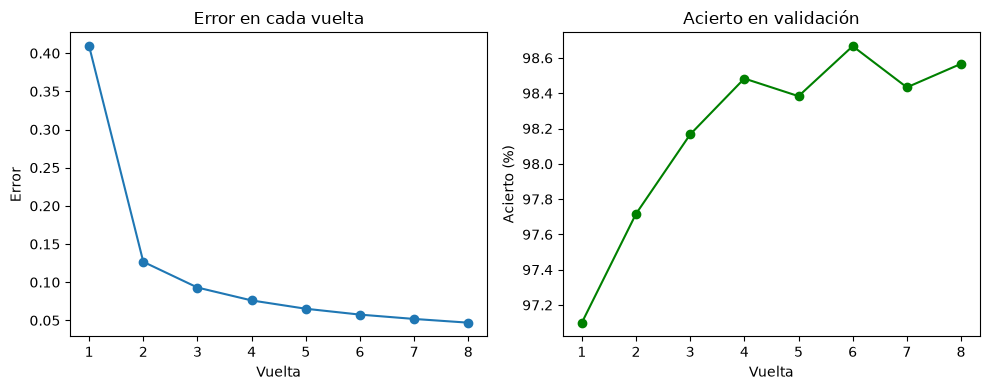

In [22]:
vueltas = range(1, len(historia_acierto) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(vueltas, historia_error, marker="o")
plt.title("Error en cada vuelta")
plt.xlabel("Vuelta")
plt.ylabel("Error")

plt.subplot(1, 2, 2)
plt.plot(vueltas, [a * 100 for a in historia_acierto], marker="o", color="green")
plt.title("Acierto en validación")
plt.xlabel("Vuelta")
plt.ylabel("Acierto (%)")

plt.tight_layout()
plt.show()

### probar la red con las 10 000 imágenes de prueba

In [23]:
from sklearn.metrics import accuracy_score, precision_score

Xts_t = Xts_t.to(dispositivo)

modelo.eval()
with torch.no_grad():
    pred_prueba = modelo(Xts_t).argmax(1).cpu().numpy()

exactitud = accuracy_score(Yts, pred_prueba)
precision = precision_score(Yts, pred_prueba, average="macro")

p("Exactitud:", round(exactitud, 4))
p("Precisión:", round(precision, 4))

Exactitud: 0.9869
Precisión: 0.9871


### ver la precisión 

In [24]:
precision_digitos = precision_score(Yts, pred_prueba, average=None)

tabla_digitos = pd.DataFrame({
    "dígito": range(10),
    "precisión": precision_digitos.round(4)
})
d(tabla_digitos)

,dígito,precisión
0,0,0.9879
1,1,0.9852
2,2,0.9864
3,3,0.9862
4,4,0.9908
5,5,0.9921
6,6,0.9989
7,7,0.9768
8,8,0.9846
9,9,0.9821


### dibujar la matriz de confusión

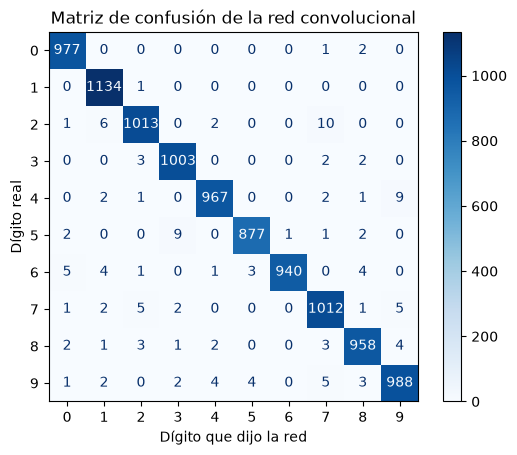

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(Yts, pred_prueba, cmap="Blues")
plt.title("Matriz de confusión de la red convolucional")
plt.xlabel("Dígito que dijo la red")
plt.ylabel("Dígito real")
plt.show()


### ver imágenes donde la red se equivocó

Total de errores: 131 de 10000


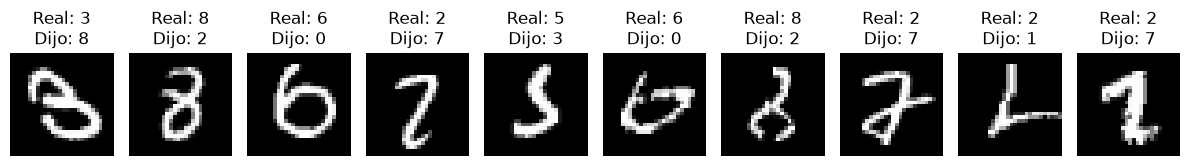

In [26]:
errores = np.where(pred_prueba != Yts)[0]
p("Total de errores:", len(errores), "de", len(Yts))

plt.figure(figsize=(12, 3))
for i in range(10):
    n = errores[i]
    plt.subplot(1, 10, i + 1)
    plt.imshow(Xts[n].reshape(28, 28), cmap="gray")
    plt.title(f"Real: {Yts[n]}\nDijo: {pred_prueba[n]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### comparar la red convolucional con los modelos del cuaderno 03

In [29]:
comparacion = pd.DataFrame({
    "modelo": ["Red convolucional", "SVM", "KNN", "Regresión logística", "Árbol de decisión", "Regresión lineal"],
    "exactitud": [round(exactitud, 4), 0.9767, 0.9705, 0.9260, 0.8754, 0.2260],
    "precisión": [round(precision, 4), 0.9768, 0.9709, 0.9250, 0.8740, 0.2808]
})
d(comparacion)

,modelo,exactitud,precisión
0,Red convolucional,0.9869,0.9871
1,SVM,0.9767,0.9768
2,KNN,0.9705,0.9709
3,Regresión logística,0.9260,0.9250
4,Árbol de decisión,0.8754,0.8740
5,Regresión lineal,0.2260,0.2808


### guardar la red entrenada en la carpeta modelos

In [30]:
Carpeta_modelos = Carpeta_Proyecto / "modelos"
Carpeta_modelos.mkdir(exist_ok=True)

torch.save(modelo.state_dict(), Carpeta_modelos / "red_digitos.pt")
p("Red guardada en:", Carpeta_modelos / "red_digitos.pt")

Red guardada en: /home/Ian/prediccion_red/modelos/red_digitos.pt


### copiar el diseño de la red 

In [31]:
%%writefile ../src/red.py
import numpy as np
import torch
from torch import nn


class RedConvolucional(nn.Module):
    def __init__(self, n_salidas=10, abandono=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.agrupar = nn.MaxPool2d(2)
        self.activacion = nn.ReLU()
        self.aplanar = nn.Flatten()
        self.densa1 = nn.Linear(32 * 7 * 7, 64)
        self.abandono = nn.Dropout(abandono)
        self.densa2 = nn.Linear(64, 32)
        self.salida = nn.Linear(32, n_salidas)

    def forward(self, x):
        c1 = self.agrupar(self.activacion(self.conv1(x)))
        c2 = self.agrupar(self.activacion(self.conv2(c1)))
        d1 = self.activacion(self.densa1(self.aplanar(c2)))
        d2 = self.activacion(self.densa2(self.abandono(d1)))
        s = self.salida(d2)
        return s

Writing ../src/red.py


### función que arma la red y le carga lo que aprendió

In [32]:
%%writefile -a ../src/red.py


def cargar_red(ruta, n_salidas=10):
    red = RedConvolucional(n_salidas=n_salidas)
    red.load_state_dict(torch.load(ruta, map_location="cpu"))
    red.eval()
    return red

Appending to ../src/red.py


### función que mira cada imagen de 28×28 y dice qué número es

In [33]:
%%writefile -a ../src/red.py


def predecir(red, imagenes):
    x = torch.tensor(np.array(imagenes) / 255.0, dtype=torch.float32).reshape(-1, 1, 28, 28)
    with torch.no_grad():
        probabilidades = torch.softmax(red(x), dim=1)
    seguridad, respuesta = probabilidades.max(1)
    return respuesta.numpy(), seguridad.numpy()

Appending to ../src/red.py
